In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

In [2]:
pois = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/delhi_pois.geojson")
wards = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/wards_delhi_c.geojson")

In [3]:
print("Number of POIs:", len(pois))
print("CRS:", pois.crs)
print("Columns:", pois.columns.tolist())

display(pois.head())

Number of POIs: 50740
CRS: EPSG:4326
Columns: ['sl_no', 'PoI_Type', 'Latitude', 'Longitude', 'geometry']


,sl_no,PoI_Type,Latitude,Longitude,geometry
0,1,Parks,28.469460,77.122980,POINT (77.12298 28.46946)
1,2,Schools,28.437668,77.141225,POINT (77.14122 28.43767)
2,3,Parks,28.438900,77.142180,POINT (77.14218 28.4389)
3,4,Playgrounds_Open_Source,28.447527,77.138000,POINT (77.138 28.44753)
4,5,amenity,28.452406,77.141672,POINT (77.14167 28.45241)


In [4]:
pois["PoI_Type"].value_counts().head(20)

PoI_Type
ATM                                         8133
amenity                                     7722
Schools                                     5638
Parks                                       3911
Bank Branch                                 3724
Bank Mitra                                  3680
shop                                        3257
PDS_Open_Source                             2255
Playgrounds_Open_Source                     1837
Sports Facilities                           1448
Fountain_Open_Source                        1324
Fire_Hydrant_Open_Source                    1014
Slums_Redevelopment_Colonies_Open_Source     840
Hospitals                                    828
tourism                                      789
CSC_NIC_Through_API                          629
leisure                                      601
Post Offices                                 514
office                                       448
Police_Station_Open_Source                   340
Name: count

In [5]:
print("Number of wards:", len(wards))
print("CRS:", wards.crs)

display(wards.head())

Number of wards: 290
CRS: EPSG:4326


,Ward_Name,Ward_No,geometry
0,DELHI CANTT CHARGE 1,CANT_1,"POLYGON ((77.13228 28.63154, 77.13644 28.62062..."
1,DELHI CANTT CHARGE 2,CANT_2,"POLYGON ((77.15429 28.62335, 77.15501 28.62228..."
2,DELHI CANTT CHARGE 4,CANT_4,"POLYGON ((77.15755 28.57578, 77.15672 28.57564..."
3,DELHI CANTT CHARGE 5,CANT_5,"POLYGON ((77.1348 28.57051, 77.13429 28.57048,..."
4,DELHI CANTT CHARGE 6,CANT_6,"POLYGON ((77.12157 28.59308, 77.12878 28.59029..."


In [6]:
pois_utm = pois.to_crs(epsg=32643)
wards_utm = wards.to_crs(epsg=32643)

print("POI CRS:", pois_utm.crs)
print("Ward CRS:", wards_utm.crs)

POI CRS: EPSG:32643
Ward CRS: EPSG:32643


In [7]:
education = pois_utm[
    pois_utm["PoI_Type"].str.contains(
        "school|college|university",
        case=False,
        na=False
    )
].copy()

print("Education-related POIs:", len(education))

display(
    education[["PoI_Type", "geometry"]].head()
)

Education-related POIs: 5638


,PoI_Type,geometry
1,Schools,POINT (709700.762 3147553.161)
16,Schools,POINT (708394.776 3151297.311)
18,Schools,POINT (707951.81 3151380.265)
20,Schools,POINT (707825.429 3151575.138)
23,Schools,POINT (708436.435 3152069.522)


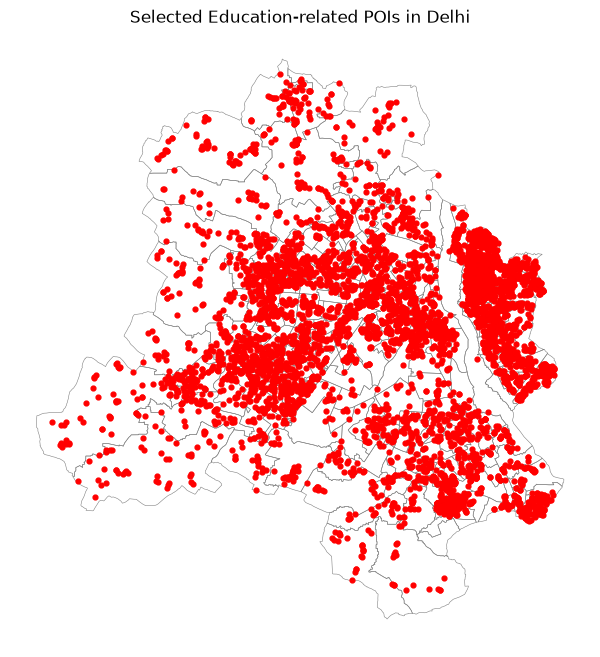

In [8]:
fig, ax = plt.subplots(figsize=(9, 8))

wards_utm.boundary.plot(
    ax=ax,
    color="grey",
    linewidth=0.4,
    zorder=1
)

education.plot(
    ax=ax,
    color="red",
    markersize=12,
    zorder=2
)

ax.set_title("Selected Education-related POIs in Delhi")
ax.set_axis_off()

plt.show()

In [10]:
education_buffer = education.copy()

education_buffer["geometry"] = (
    education_buffer.geometry.buffer(500)
)

display(
    education_buffer[["PoI_Type", "geometry"]].head()
)

,PoI_Type,geometry
1,Schools,"POLYGON ((710200.762 3147553.161, 710198.354 3..."
16,Schools,"POLYGON ((708894.776 3151297.311, 708892.369 3..."
18,Schools,"POLYGON ((708451.81 3151380.265, 708449.402 31..."
20,Schools,"POLYGON ((708325.429 3151575.138, 708323.021 3..."
23,Schools,"POLYGON ((708936.435 3152069.522, 708934.028 3..."


In [11]:
print("Original geometry:")
print(education.geom_type.value_counts())

print("\nBuffered geometry:")
print(education_buffer.geom_type.value_counts())

Original geometry:
Point    5638
Name: count, dtype: int64

Buffered geometry:
Polygon    5638
Name: count, dtype: int64


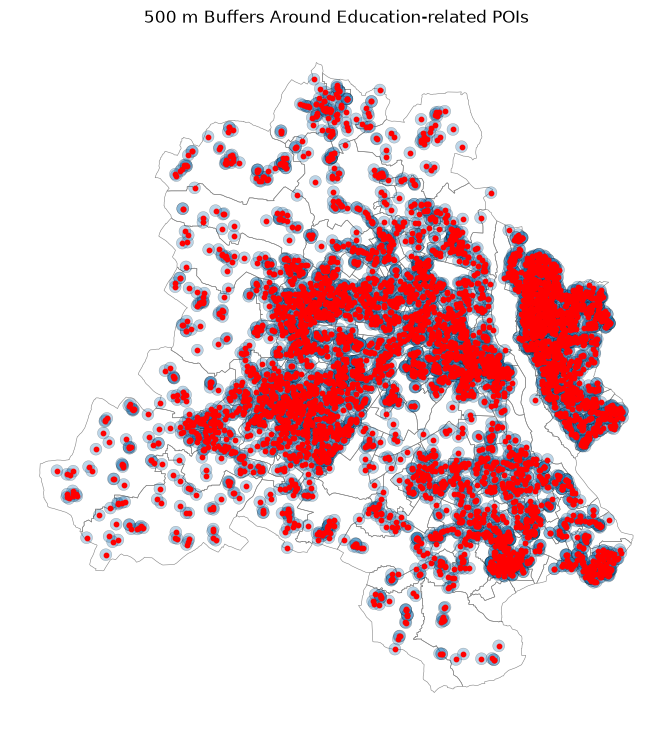

In [12]:
fig, ax = plt.subplots(figsize=(10, 9))

# Delhi ward boundaries
wards_utm.boundary.plot(
    ax=ax,
    color="grey",
    linewidth=0.4,
    zorder=1
)

# 500 m buffer polygons
education_buffer.plot(
    ax=ax,
    alpha=0.30,
    edgecolor="black",
    linewidth=0.3,
    zorder=2
)

# Original education POI points
education.plot(
    ax=ax,
    color="red",
    markersize=10,
    zorder=3
)

ax.set_title("500 m Buffers Around Education-related POIs")
ax.set_axis_off()

plt.show()

In [13]:
education_coverage = education_buffer.dissolve()

display(education_coverage)

,geometry,sl_no,PoI_Type,Latitude,Longitude
0,"MULTIPOLYGON (((685592.553 3155029.294, 685546...",2,Schools,28.437668,77.141225


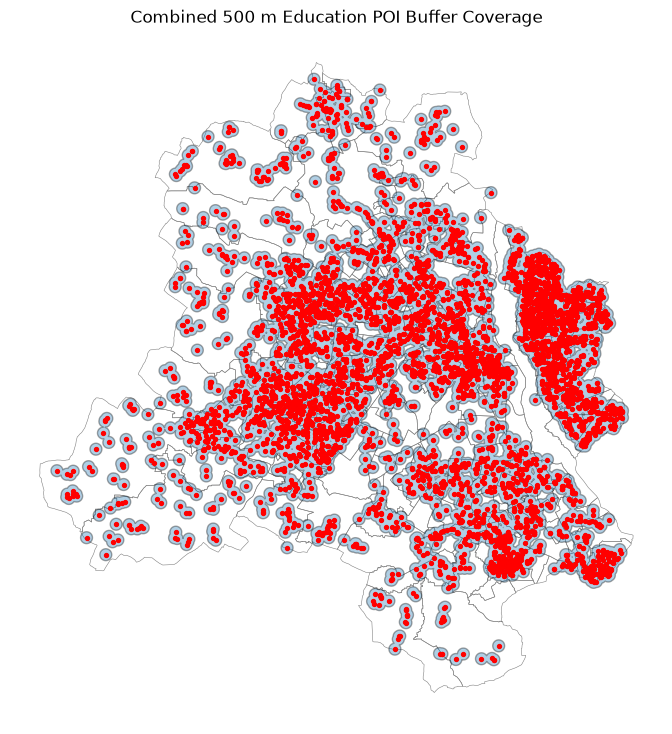

In [14]:
fig, ax = plt.subplots(figsize=(10, 9))

wards_utm.boundary.plot(
    ax=ax,
    color="grey",
    linewidth=0.4,
    zorder=1
)

education_coverage.plot(
    ax=ax,
    alpha=0.35,
    edgecolor="black",
    zorder=2
)

education.plot(
    ax=ax,
    color="red",
    markersize=8,
    zorder=3
)

ax.set_title("Combined 500 m Education POI Buffer Coverage")
ax.set_axis_off()

plt.show()

In [15]:
education_coverage["area_km2"] = (
    education_coverage.geometry.area / 1_000_000
)

education_coverage[["area_km2"]]

,area_km2
0,837.642843
